# Lecture 17: Transfer learning

Pretrained models let us reuse what a neural network learned from a large dataset. We can use them in three ways:

1. **Use them out of the box:** keep the pretrained model, including its classifier, and predict its original labels without training.
2. **Use frozen weights:** keep the pretrained CNN fixed as a feature extractor and train a new classifier for our own labels.
3. **Fine-tune:** train some or all of the pretrained CNN weights on our new task, along with a task-specific classifier.

We will first classify images with an out-of-the-box ImageNet model, then use frozen features to learn seven food categories. We will finish by discussing fine-tuning.


## Setup and imports

- Run cells in order using this directory's `.venv`, with `content/classes/varada` as the working directory.
- Dependencies: PyTorch, torchvision, scikit-learn, NumPy, pandas, Pillow, and Matplotlib.
- For the out-of-the-box demo, use the images in `data/test_images/`.
- For the frozen-weights demo, use the small [Food-101](https://www.kaggle.com/datasets/kmader/food41) subset in `data/food-transfer-learning/`, with `train/` and `valid/` folders containing one subfolder per category.
- The first run may download pretrained MobileNet weights. Inference and feature extraction run on CUDA, Apple Silicon, or CPU.
- For this demo, **reserve the existing `valid/` folder for final evaluation**. Select models using CV within `train/` only. A final evaluation is independent only if these held-out images have not already influenced model choices.

This follows HW7's modelling workflow on a different image task. HW7 creates its own stratified train/test split rather than using these folders.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(42)
plt.rcParams["font.size"] = 14
pd.set_option("display.max_colwidth", 120)

DATA_DIR = Path("data")
# Use a GPU when available, including Apple Silicon GPUs via MPS.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("Device:", DEVICE)


Device: mps


## 1. Use a pretrained model out of the box

Keep MobileNet's original classifier to predict the 1,000 ImageNet categories. No training is needed: use the resizing, cropping, and normalization supplied with the pretrained weights, then convert the model's scores to probabilities with softmax.

**Predict:** Which of our test images fit ImageNet's categories? What might happen for a campus scene or an unfamiliar object?


In [2]:
weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
imagenet_preprocess = weights.transforms()
imagenet_labels = weights.meta["categories"]
imagenet_model = models.mobilenet_v3_small(weights=weights).to(DEVICE).eval()
imagenet_model.requires_grad_(False)


def classify_image(image_path, topn=5):
    """Return the top ImageNet labels and probabilities without training."""
    with Image.open(image_path) as image:
        inputs = imagenet_preprocess(image.convert("RGB")).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        probabilities = imagenet_model(inputs).softmax(dim=1)[0]
        top_probabilities, top_indices = probabilities.topk(topn)
    return pd.DataFrame({
        "label": [imagenet_labels[index] for index in top_indices.cpu().tolist()],
        "probability": top_probabilities.cpu().tolist(),
    })


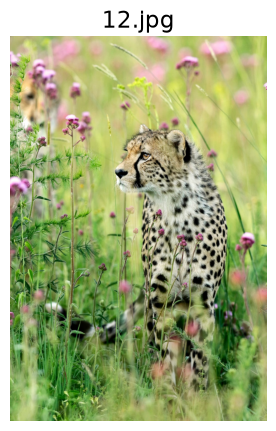

       label  probability
     cheetah     0.973194
     leopard     0.023899
      jaguar     0.001837
snow leopard     0.000904
        lynx     0.000113
--------------------------------------------------------------


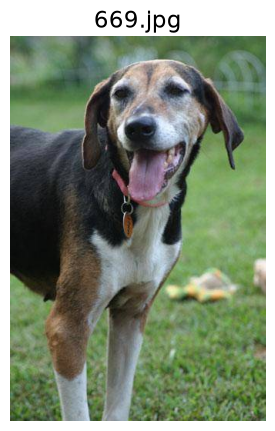

                     label  probability
               EntleBucher     0.237392
Greater Swiss Mountain dog     0.234903
                    beagle     0.162165
               Appenzeller     0.151979
              Walker hound     0.147873
--------------------------------------------------------------


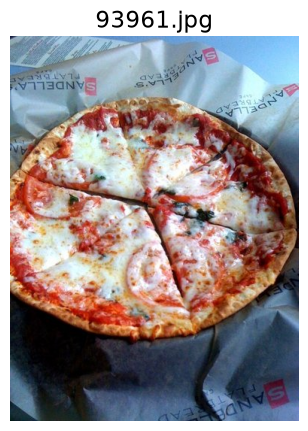

     label  probability
     pizza     0.995856
frying pan     0.002404
    potpie     0.000631
 meat loaf     0.000120
 king crab     0.000085
--------------------------------------------------------------


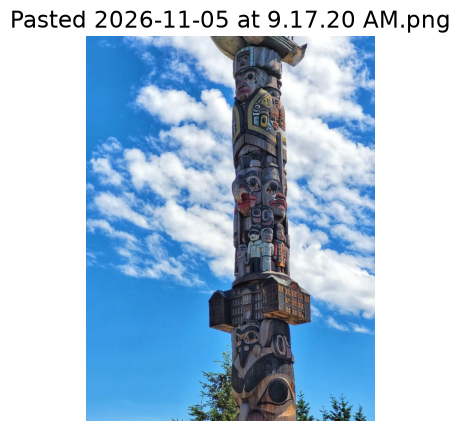

     label  probability
totem pole     0.932166
      pole     0.054407
  pedestal     0.005262
   obelisk     0.004031
    mosque     0.000605
--------------------------------------------------------------


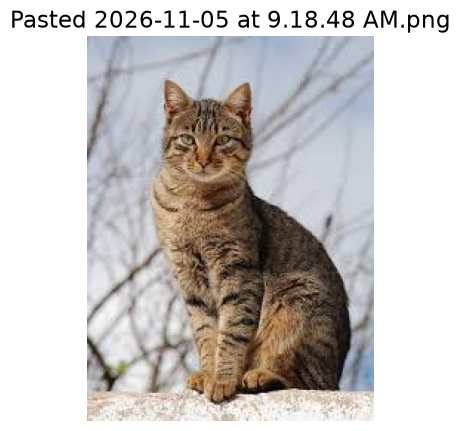

       label  probability
Egyptian cat     0.597165
   tiger cat     0.205065
       tabby     0.190864
        lynx     0.004797
      coyote     0.000918
--------------------------------------------------------------


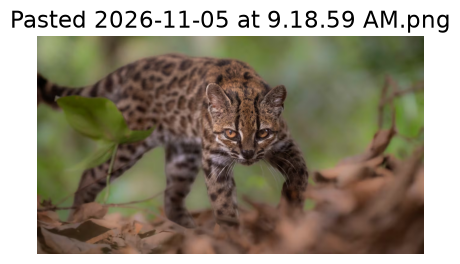

       label  probability
      jaguar     0.546107
     leopard     0.399937
        lynx     0.033956
snow leopard     0.013711
Egyptian cat     0.001914
--------------------------------------------------------------


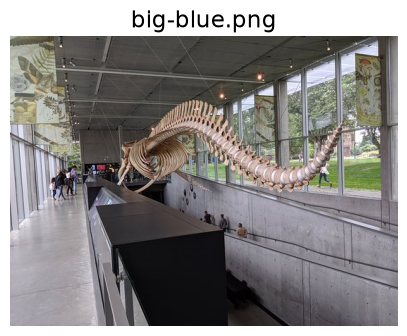

      label  probability
       harp     0.515572
triceratops     0.088901
  amphibian     0.047877
   schooner     0.047612
  submarine     0.022563
--------------------------------------------------------------


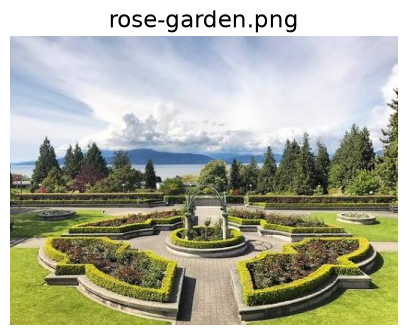

     label  probability
      maze     0.800221
worm fence     0.179047
    palace     0.004264
   sundial     0.001908
 tile roof     0.001886
--------------------------------------------------------------


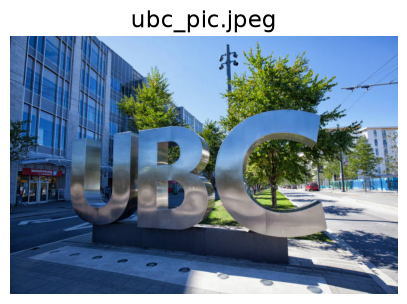

     label  probability
car mirror     0.211597
       tub     0.092334
sunglasses     0.077130
  fountain     0.075754
  sunglass     0.050635
--------------------------------------------------------------


In [3]:
# Predict top labels and their associated probabilities for unseen images.
images = sorted(
    path for path in (DATA_DIR / "test_images").iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)
for img_path in images:
    with Image.open(img_path) as image:
        img = image.convert("RGB")
        img.load()
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(img_path.name)
    plt.axis("off")
    plt.show()
    df = classify_image(img_path)
    print(df.to_string(index=False))
    print("--------------------------------------------------------------")


**Discuss:** Looking at the test images and their top-five predictions, when does the out-of-the-box model succeed, and when does it fail? What might explain the difference, and does a high predicted probability always mean the model is correct?

<details>
<summary>Reveal model answer</summary>

The model tends to succeed when an image contains a clear object from one of ImageNet's categories and resembles the images used to train it. Look for examples where the correct label appears first or among the top five; related labels can also indicate that the model recognizes useful visual features.

It can fail when the subject has no suitable ImageNet label, when a scene contains several objects without a single obvious subject, or when lighting, viewpoint, background, or image quality differs from its training data. For example, a campus photograph may receive a label for a visible object rather than identify the campus; the model can only choose from its 1,000 original categories. Its preprocessing may also crop out useful context.

A high probability does not guarantee correctness: softmax distributes probability among the available labels even when none fits well. These examples suggest where the model may be useful, but we would need labeled images representative of our intended task to measure how often it succeeds.

</details>

To predict our own seven food labels, we will replace the original classifier and learn a new one from frozen CNN features.


## 2. Use frozen weights for a new task

Our food-classification workflow keeps the pretrained CNN fixed and trains a new classifier. We will compare learned features with pixels, select regularization using cross-validation, and evaluate on reserved images.

**Predict:** Can we learn seven food categories without training a CNN from scratch?


### 2.1. Inspect the food images and labels

`ImageFolder` uses subfolder names as labels. Check that the integer-to-label mapping agrees across splits. Keep duplicate images and photographs of the same meal in the same split when preparing a dataset.

**Predict:** What accuracy would a most-frequent classifier achieve on roughly balanced seven-class data?


In [4]:
food_dir = DATA_DIR / "food-transfer-learning"
for split in ["train", "valid"]:
    if not (food_dir / split).is_dir():
        raise FileNotFoundError(f"Required image folder: {(food_dir / split).resolve()}")
food_train = datasets.ImageFolder(food_dir / "train")
food_valid = datasets.ImageFolder(food_dir / "valid")
assert food_train.class_to_idx == food_valid.class_to_idx
class_names = food_train.classes
counts = pd.DataFrame({
    "training images": pd.Series(food_train.targets).value_counts(),
    "held-out images": pd.Series(food_valid.targets).value_counts(),
}).reindex(range(len(class_names)), fill_value=0)
counts.index = class_names
display(counts)
print("Training majority proportion:", counts["training images"].max() / len(food_train))


,training images,held-out images
beet_salad,40,10
chocolate_cake,38,9
edamame,40,10
french_fries,40,10
pizza,43,10
spring_rolls,41,9
sushi,41,9


Training majority proportion: 0.1519434628975265


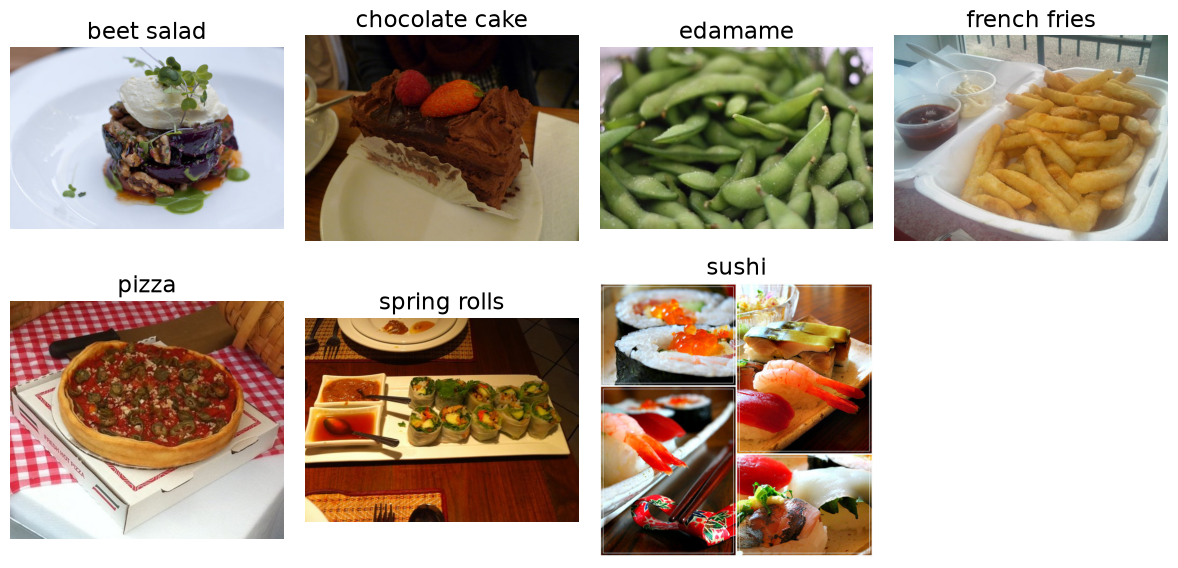

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, class_name in zip(axes.flat, food_train.classes):
    class_index = food_train.class_to_idx[class_name]
    image_index = food_train.targets.index(class_index)
    image, _ = food_train[image_index]
    ax.imshow(image)
    ax.set_title(class_name.replace("_", " "))
    ax.axis("off")
axes.flat[-1].axis("off")
plt.tight_layout()


### 2.2. Reuse a pretrained feature extractor

![MobileNetV3-Small architecture illustration. AI-generated using OpenAI's ChatGPT (2026)](img/MobileNetV3-Small-Overview.png)


Our workflow is **image → fixed MobileNet preprocessing → frozen CNN → 576 features → scaler → logistic regression**.

MobileNet learned its weights from ImageNet. Replacing its original classifier with `Identity` returns features instead of its 1,000 original class scores. Our logistic regression learns the seven food labels. Those labels do not need to match ImageNet's categories.

- `weights.transforms()` supplies the fixed resizing, cropping, and normalization expected by the pretrained weights.
- `requires_grad_(False)` freezes parameters; `eval()` sets prediction behaviour; `inference_mode()` avoids gradient tracking.
- `shuffle=False` preserves image order so feature rows, labels, and displayed images remain aligned.

**Predict:** Does extracting features from a held-out image update the CNN?


In [6]:
# Reuse the same pretrained weights and preprocessing from part 1.
feature_model = models.mobilenet_v3_small(weights=weights)
feature_model.classifier = nn.Identity() # bypasses the classifier
feature_model.requires_grad_(False) # freeze the CNN
feature_model = feature_model.to(DEVICE).eval()


def make_loader(split):
    dataset = datasets.ImageFolder(food_dir / split, transform=imagenet_preprocess)
    assert dataset.class_to_idx == food_train.class_to_idx
    reference = food_train if split == "train" else food_valid
    assert dataset.samples == reference.samples
    return DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)


def extract_features(model, data_loader, device):
    """Return feature rows and labels in loader order without updating weights."""
    model.eval()
    feature_batches, target_batches = [], []
    with torch.inference_mode():
        for images, targets in data_loader:
            feature_batches.append(model(images.to(device)).cpu())
            target_batches.append(targets)
    return torch.cat(feature_batches).numpy(), torch.cat(target_batches).numpy()


Z_train, y_train = extract_features(feature_model, make_loader("train"), DEVICE)
np.testing.assert_array_equal(y_train, food_train.targets)
assert Z_train.shape == (len(food_train), 576)
assert not any(p.requires_grad for p in feature_model.parameters())
print("Training feature matrix:", Z_train.shape)
print("Training targets:", y_train.shape)


Training feature matrix: (283, 576)
Training targets: (283,)


**Inspect:** Each row is an image; each column is a learned feature, not a food probability.

<details>
<summary>Reveal explanation: what learns from which data?</summary>

The CNN learned from ImageNet and stays fixed here. Image preprocessing is fixed by its weights. The scaler learns feature means and scales, and logistic regression learns coefficients, from food training examples. Frozen deterministic features can be extracted once before CV because this step learns nothing from our food images. Scaling must be fitted separately inside each CV fold.

</details>


### 2.3. Compare representations with cross-validation

For a simple alternative, resize each image to 16 × 16 RGB pixels and flatten it into 768 values. Compare this representation with the 576 pretrained features using the same `StandardScaler` → `LogisticRegression` pipeline, `C=1`, and five stratified folds.

**Predict:** Would perfect training accuracy prove that a representation generalizes well?


In [7]:
def pixel_features(dataset):
    """Return fixed low-resolution pixels in ImageFolder order."""
    rows = []
    for image, _ in dataset:
        small_image = image.convert("RGB").resize((16, 16), Image.Resampling.BILINEAR)
        rows.append(np.asarray(small_image, dtype=np.float32).ravel() / 255.0)
    return np.stack(rows)


def new_pipeline(C=1.0):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))


X_pixels_train = pixel_features(food_train)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models_to_compare = {
    "Most-frequent baseline": (DummyClassifier(strategy="most_frequent"), Z_train),
    "Pixels + logistic regression": (new_pipeline(), X_pixels_train),
    "Pretrained features + logistic regression": (new_pipeline(), Z_train),
}
comparison = {}
for name, (model, features) in models_to_compare.items():
    scores = pd.DataFrame(cross_validate(
        model, features, y_train, cv=cv, scoring="accuracy",
        return_train_score=True, n_jobs=1,
    ))
    comparison[name] = {
        "mean training accuracy": scores.train_score.mean(),
        "mean CV accuracy": scores.test_score.mean(),
        "std CV accuracy": scores.test_score.std(),
    }
display(pd.DataFrame(comparison).T.round(3))


,mean training accuracy,mean CV accuracy,std CV accuracy
Most-frequent baseline,0.152,0.152,0.011
Pixels + logistic regression,1.000,0.339,0.040
Pretrained features + logistic regression,1.000,0.845,0.071


**Inspect:** Compare mean CV accuracy with the dummy baseline and examine training–CV gaps. Resolve convergence warnings before interpreting the scores.

<details>
<summary>Reveal explanation: reading the table</summary>

High training accuracy can coexist with poor generalization. CV accuracy evaluates held-out training folds; its standard deviation describes variation across those folds, not a confidence interval. `cross_validate`'s `test_score` refers to CV folds, not the reserved final set. This compares two particular representations and preprocessing choices, not every possible pixel-based model.

</details>


### 2.4. Select regularization using training folds only

Smaller `C` means stronger regularization. Reuse the extracted features and tune only the sklearn pipeline. Keep the scaler inside the pipeline so each fold fits its own means and scales.

**Predict:** As `C` increases, must CV accuracy increase along with training accuracy?


,param_logisticregression__C,mean_train_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
1,0.010,1.000000,0.866040,0.038661,0.005723,1
2,0.100,1.000000,0.862594,0.050705,0.005557,2
0,0.001,0.956719,0.858835,0.028654,0.005944,3
3,1.000,1.000000,0.844987,0.063475,0.004562,4
4,10.000,1.000000,0.841479,0.067790,0.002427,5
5,100.000,1.000000,0.834461,0.075951,0.002458,6


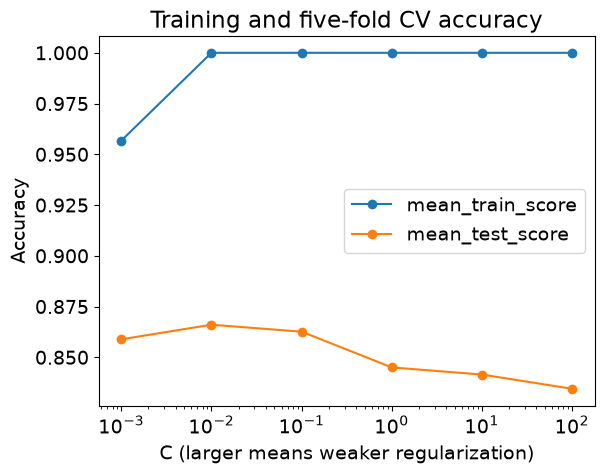

Selected C: 0.01
Selected mean CV accuracy: 0.8660401002506266


In [8]:
search = GridSearchCV(
    new_pipeline(), {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    cv=cv, scoring="accuracy", return_train_score=True, refit=True, n_jobs=1,
)
search.fit(Z_train, y_train)
grid_results = pd.DataFrame(search.cv_results_)
display(grid_results.sort_values("rank_test_score")[[
    "param_logisticregression__C", "mean_train_score", "mean_test_score",
    "std_test_score", "mean_fit_time", "rank_test_score",
]])
ax = grid_results.plot(
    x="param_logisticregression__C", y=["mean_train_score", "mean_test_score"],
    logx=True, marker="o",
)
ax.set(xlabel="C (larger means weaker regularization)", ylabel="Accuracy",
       title="Training and five-fold CV accuracy")
plt.show()
best_C = float(search.best_params_["logisticregression__C"])
best_model = search.best_estimator_
print("Selected C:", best_C)
print("Selected mean CV accuracy:", search.best_score_)


**Discuss:** Does increasing `C` help held-out folds, mainly help training accuracy, or neither?

<details>
<summary>Reveal explanation: refitting and leakage</summary>

`refit=True` fits the selected scaler and classifier afresh on all training feature rows. The highest CV score helped select `C`, so it is not an independent final estimate. Fitting `StandardScaler` before CV would expose held-out folds through their means and scales. Fine-tuning the CNN on all training images before CV would also expose held-out folds to learned weights; our frozen extractor does not do that.

</details>


### 2.5. Evaluate the selected model on reserved images

Model selection is complete. Now use the existing `valid/` folder as the final holdout, without further tuning. Extract its features with the same frozen model and preprocessing. No new `fit` call is needed.

**Predict:** Could high overall accuracy hide a food category with poor recall?


Selected mean CV accuracy: 0.8660401002506266
Final held-out accuracy: 0.8805970149253731
                precision    recall  f1-score   support

    beet_salad       0.90      0.90      0.90        10
chocolate_cake       0.90      1.00      0.95         9
       edamame       1.00      0.90      0.95        10
  french_fries       0.89      0.80      0.84        10
         pizza       0.83      1.00      0.91        10
  spring_rolls       0.78      0.78      0.78         9
         sushi       0.88      0.78      0.82         9

      accuracy                           0.88        67
     macro avg       0.88      0.88      0.88        67
  weighted avg       0.88      0.88      0.88        67



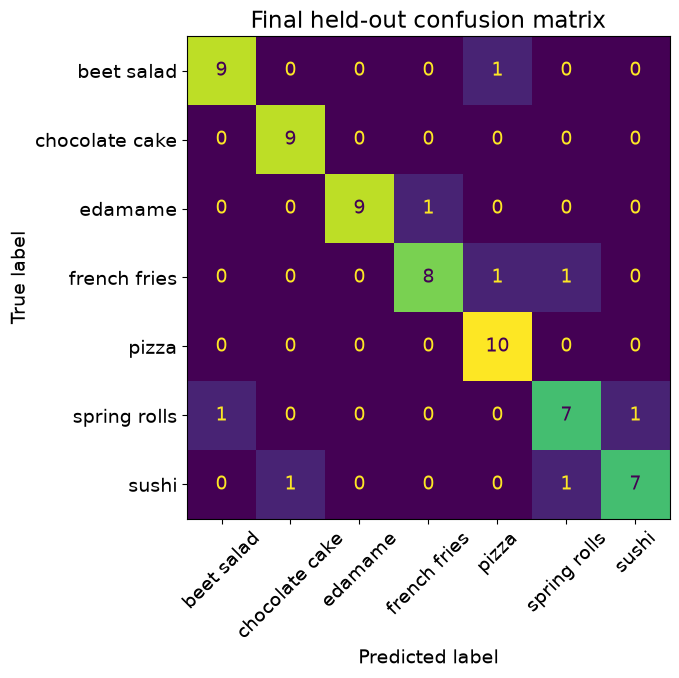

In [9]:
Z_valid, y_valid = extract_features(feature_model, make_loader("valid"), DEVICE)
np.testing.assert_array_equal(y_valid, food_valid.targets)
valid_predictions = best_model.predict(Z_valid)
print("Selected mean CV accuracy:", search.best_score_)
print("Final held-out accuracy:", best_model.score(Z_valid, y_valid))
print(classification_report(
    y_valid, valid_predictions, labels=np.arange(len(class_names)),
    target_names=class_names, zero_division=0,
))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_valid, valid_predictions, labels=np.arange(len(class_names)),
    display_labels=[name.replace("_", " ") for name in class_names],
    xticks_rotation=45, ax=ax, colorbar=False,
)
ax.set_title("Final held-out confusion matrix")
plt.tight_layout()
plt.show()


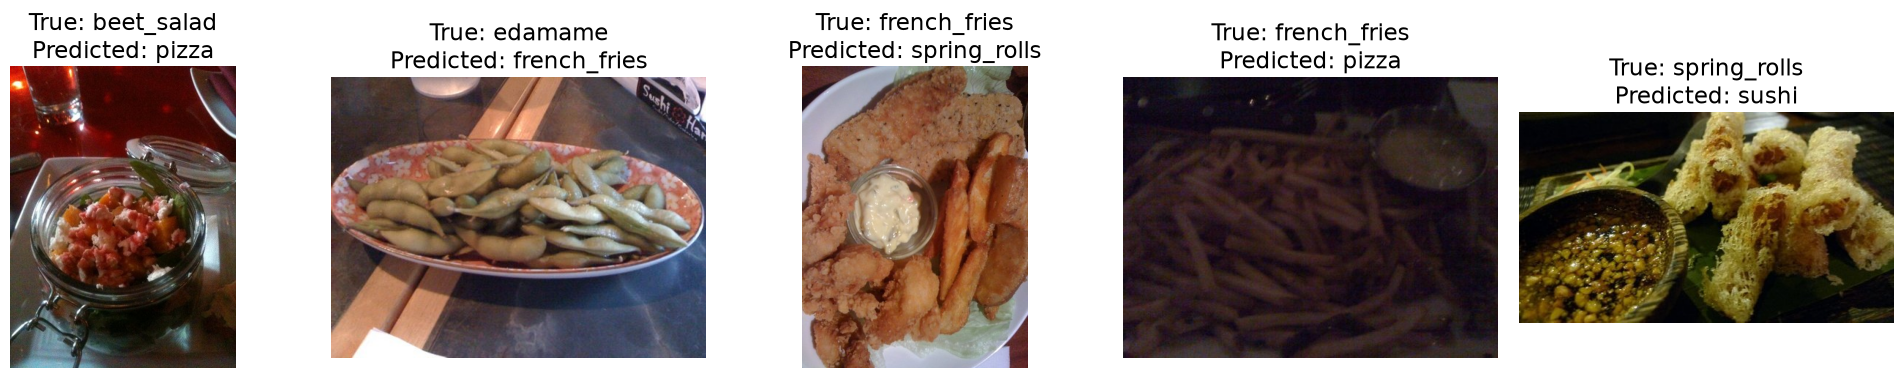

In [10]:
valid_predictions = best_model.predict(Z_valid)
error_indices = np.flatnonzero(valid_predictions != y_valid)[:5]
if len(error_indices):
    fig, axes = plt.subplots(1, len(error_indices), figsize=(4 * len(error_indices), 4), squeeze=False)
    for ax, index in zip(axes.flat, error_indices):
        image_path, _ = food_valid.samples[index]
        ax.imshow(Image.open(image_path).convert("RGB"))
        ax.set_title(f"True: {class_names[y_valid[index]]}\nPredicted: {class_names[valid_predictions[index]]}")
        ax.axis("off")
    plt.tight_layout()
else:
    print("No validation mistakes; a small validation set still leaves uncertainty.")


**Inspect:** Identify two observations supported by the confusion matrix and displayed errors. Visual similarity may suggest an explanation, but does not prove which cues the model used.

Do not tune again using these results. If we use these images to change the workflow, they become development data and we need a fresh test set. A small holdout also leaves uncertainty about performance on new photographs.


### 2.6. Predict one image using the same workflow

Apply the same image transform, frozen extractor, and fitted pipeline. Do not fit a scaler to the incoming image.

**Predict:** What will this seven-class model do if we give it a photograph of a bicycle?


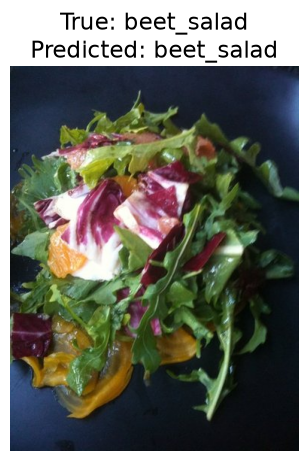

In [11]:
def predict_food(image_path):
    image = Image.open(image_path).convert("RGB")
    inputs = imagenet_preprocess(image).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        features = feature_model(inputs).cpu().numpy()
    label_index = int(best_model.predict(features)[0])
    return class_names[label_index]


# Demonstrate on a held-out validation image; replace this path for a new photo.
example_path, true_index = food_valid.samples[0]
predicted_label = predict_food(example_path)
plt.figure(figsize=(5, 5))
plt.imshow(Image.open(example_path).convert("RGB"))
plt.title(f"True: {class_names[true_index]}\nPredicted: {predicted_label}")
plt.axis("off");
assert predicted_label == class_names[int(valid_predictions[0])]


<details>
<summary>Reveal explanation: predictions and unfamiliar images</summary>

The classifier always chooses one of its seven food labels, even for a bicycle. A single prediction demonstrates the workflow; it does not measure deployment accuracy. New lighting, backgrounds, mixed dishes, and unfamiliar categories can reduce performance. High confidence alone does not establish that an image belongs to a known class.

</details>


### 2.7. Check your interpretation

Select all statements that are **true**:

- **A.** The CNN learns new weights when we call `extract_features`.
- **B.** Frozen deterministic features can be reused across CV folds and different values of `C`.
- **C.** Scaling all food features before CV gives the same leakage protection as using a pipeline.
- **D.** `best_model` has been refitted on all training features by `GridSearchCV`.
- **E.** Changing image preprocessing requires extracting features again.

<details>
<summary>Reveal answers</summary>

**B, D, and E.** The CNN stays frozen. Scaling learns from the supplied rows, so it must remain inside the CV pipeline. Changing `C` requires refitting the scaler/classifier pipeline but no new CNN inference. Changing the CNN weights or image preprocessing requires recomputing features.

</details>


### 2.8. Connection to HW7

| Demo step | HW7 application |
| --- | --- |
| Read food folders and check label mapping | Load cleaned waste images and make a stratified train/test split |
| Extract 576 frozen MobileNet features in order | Preserve feature/target alignment with the supplied index-based loaders |
| Compare dummy, pixels, and CNN features on identical folds | Interpret CV means, variation, and training–CV gaps |
| Tune `C` with scaling inside the pipeline | Select and refit using training data only |
| Evaluate the reserved folder once | Report final test metrics, inspect mistakes, and assess application limits |
| Repeat the prediction workflow for one image | Apply the same transforms, extractor, and fitted pipeline to a new photograph |

**Discuss:** Would these results justify using the food model to identify allergens? What evidence would be missing?

Our labels describe food categories, not ingredients or allergen safety. Evaluate the task actually required, including unfamiliar images and realistic collection conditions. HW7 similarly asks whether recognizing material categories is enough to recommend waste-sorting deployment.


## 3. Fine-tune the pretrained model

Fine-tuning replaces the original classifier and updates some or all of the pretrained CNN weights on labeled examples from the new task, usually with a small learning rate to preserve useful learned features. Unlike frozen feature extraction, it requires training the CNN within each training split and recomputing features as weights change; use validation data to choose settings and keep a final test set untouched.
